# From Traces to Training Data: Three Datasets from One Month of Support Sessions

For sixteen days in September 2026, Ada answered questions on Calderwood
Insurance's claims desk.

When she knew the answer, she gave it. When she didn't, she said so, a senior
handler answered instead, and Ada wrote the answer to memory. The next time
someone asked, she found it there.

That is learning in token space, and it worked: by 16 September Ada held 48
memory units, and every one of them had been recalled in a later session. But
it left something behind that memory alone doesn't use. **Every session was
recorded.** The question, what Ada searched, what she said, who corrected her,
what she stored, and whether the handler was satisfied.

A record like that is training data. It says which memory answers which
question, which answer a person accepted, and which reply a person had to
replace. This notebook reads the records and turns them into three datasets,
one for each set of weights the next three notebooks change.

It is the first of four notebooks in `beyond_the_context_window/`, all set at
**Calderwood Insurance**, a fictional UK insurer. Everything about Calderwood
is invented, so no model knows any of it before it is told. This notebook
needs no model and no API key; it reads files and writes files.

## Key takeaways

- ***A trace records what happened; a dataset decides what should happen next time.*** *Selection is the step between them, and it is where most of the judgement goes.*
- ***Session outcomes are too coarse.*** *All 37 sessions say `resolved`, yet 48 of the exchanges inside them began with Ada failing. The signal lives at the level of the exchange.*
- ***A person supplies the label.*** *A senior handler's correction or a handler's thanks confirms an exchange. Ada's own messages confirm nothing.*
- ***Episodic detail stays in the traces.*** *Claim references and customer names are stripped before anything is written, and a check proves it.*
- ***One corpus, three datasets, three sets of weights.*** *SFT rows teach the model that answers, contrastive pairs teach the model that retrieves, and preference pairs say which of two answers is better.*
- ***Check for leakage before writing.*** *If a held-out question reaches a training file, every number in the next three notebooks is meaningless.*

## How this notebook is organised

Five parts. Each opens with what you'll learn and what you'll have at the end.

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | Ada's September, and why her traces are worth training on | The problem, the vocabulary and the architecture |
| **2 · Reading the traces** | Load the sessions, read one event by event, count what's in them | A picture of the raw material |
| **3 · Selecting high-signal exchanges** | Split sessions into exchanges, label them, strip episodic detail, apply the selection rule | 94 clean, confirmed exchanges |
| **4 · Three datasets** | SFT rows, contrastive pairs with hard negatives, preference pairs | Three datasets in memory, not yet written |
| **5 · Checks, writing and what's next** | Leakage and episodic checks, then the files and a manifest | Three JSONL files in `datasets/`, and where each goes |

### ⭐ The live path

Sections marked ⭐ are the ones to show live. In order they take about ten
minutes; everything between them is supporting detail to read afterwards.

| Stop | Section | What to show | Minutes |
|---|---|---|---|
| 1 | 1.1 ⭐ Ada's September | A miss, a correction and a recall: the three events the datasets come from | 2 |
| 2 | 2.2 ⭐ One session, event by event | The raw trace for a correction and for a recall | 2 |
| 3 | 3.2 ⭐ The outcome the session doesn't record | Every session says `resolved`; half the exchanges began with a miss | 1 |
| 4 | 4.2 ⭐ Contrastive pairs with hard negatives | One question, the unit that answers it and three neighbours that don't | 2 |
| 5 | 4.3 ⭐ Preference pairs | Ada's "I can't find that" against the senior handler's answer, and the catch | 2 |
| 6 | 5.1 ⭐ The leakage check | No held-out question in any dataset | 1 |

# Part 1 · The use case

This part is the *why*. You'll meet the desk and the assistant, see what a
support session records, and get the terms the rest of the notebook uses. No
code runs here.

## 1.1 ⭐ Ada's September

**Calderwood Insurance**, the claims desk, 1 September 2026, a little after
four in the afternoon.

**Tom Okafor**, a Grade 1 claims handler, is working a claim and types:

> *"Working CW-258647 for Ms J. Kowalski. How much goodwill can a handler approve?"*

**Ada**, the desk's support assistant, searches the knowledge base. Nothing.
She says so:

> *"I can't find that in the knowledge base. Can anyone on the desk confirm?"*

**Dev**, a Desk Lead, answers in the shorthand people use on a busy desk:

> *"You can do goodwill up to £250 yourself, out of the GDR."*

Ada writes a memory unit, `mem_0001`: *"Handlers can approve goodwill payments
up to £250 from the GDR."* Twelve days later another handler asks the same
thing in different words, Ada finds `mem_0001`, answers, and the handler says
*"Great, cheers."*

Three events, and each one is a different kind of evidence:

| Event | What it shows | What it can teach |
|---|---|---|
| **The miss** | Ada's reply when she didn't know | What a *rejected* answer looks like |
| **The correction** | A senior handler's answer, and the memory unit Ada wrote from it | What the *chosen* answer is, and which unit holds it |
| **The recall** | A different wording that found the same unit, and a handler who accepted the answer | That this question and this unit belong together |

Calderwood ran 37 such sessions between 1 and 16 September. By the end, Ada's
memory held 48 units. That memory is token-space learning: the model never
changed, and everything Ada learned reaches it as context.

## 1.2 · When token space is not enough

Token space is the right first move: it is cheap, readable and reversible. The
traces show where it runs out:

| Symptom in the traces | What is actually failing | The weights to change | Dataset | Notebook |
|---|---|---|---|---|
| The right unit exists but the search doesn't rank it first | The embedding model doesn't know Calderwood's words | The **embedder** | Contrastive pairs | 02 |
| Every answer goes to a large model, at a large model's price and latency, for a narrow set of questions | The task is scoped enough for a small model, if the small model knew the facts | A **small language model** | SFT rows | 03, 04 |
| Some replies had to be replaced by a person | The model prefers the wrong kind of answer | The **answering model's preferences** | Preference pairs | 03 (routing), later DPO |

Each step down that table costs more and is harder to inspect than editing a
memory unit, which is why the datasets have to be good: a bad memory unit is
deleted in a second, and a bad training row is buried in weights.

## 1.3 · The reference architecture

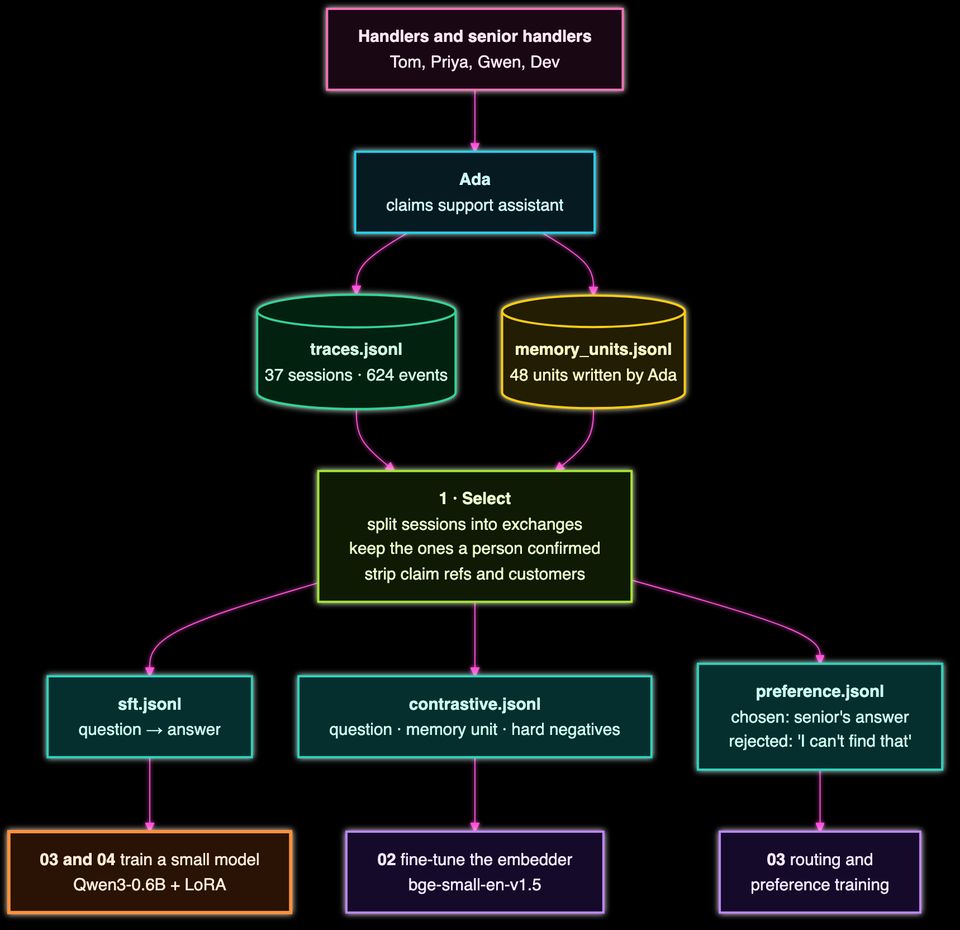

**How to read it.** Ada sits between the handlers and two stores: the traces
(what happened) and the memory units (what she wrote down). Part 3 of this
notebook is the green *Select* box. Part 4 is the three teal boxes. The bottom
row is where each dataset is used.

Seven terms carry the notebook. Each is defined once, here.

- **A trace is the recorded session: an ordered list of events (messages, tool calls, tool results) with timestamps.** Calderwood's traces are in `traces.jsonl`.
- **An exchange is one handler question and every event up to the next question.** A session holds two or three.
- **A high-signal exchange is one whose outcome a person confirmed and that is tied to a memory unit.** These are the only exchanges that become data.
- **An SFT row (supervised fine-tuning) is a chat, `system → user → assistant`, that a model is trained to complete.**
- **A contrastive pair is a question (the *anchor*) with the text that answers it (the *positive*).** Training pulls the two together and pushes everything else apart.
- **A hard negative is text that looks like the positive but doesn't answer the question.** It is the difference between learning *"this is about payout limits"* and learning *"this is the Grade 1 payout limit"*.
- **A preference pair is one prompt with two answers, one marked *chosen* and one *rejected*.** Methods such as DPO train a model to prefer the first.

> ### 📌 Key Takeaways
> - A support session records three kinds of evidence: a miss, a correction and a recall.
> - Token-space memory fixed the misses; the traces can now fix the retriever and the model.
> - Each dataset matches one failure and one set of weights.

# Part 2 · Reading the traces

This part loads the four data files and reads them before changing anything.
By the end you'll know exactly what a trace contains and what it doesn't.

## 2.1 · Setup

The notebook reads two things from beside it: the Calderwood data in
`../data/calderwood/` and the shared world in `calderwood_world.py`. It writes
one folder, `datasets/`, and only in Part 5.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `cw` (`calderwood_world`) | Calderwood world | Calderwood's people, systems, codes, customers and limits, as plain data | Its customer list is how Part 3 finds episodic detail to strip |
| `DATA`, `OUT` | Notebook setting | Where the data is read from, and where the datasets are written | Relative paths, so the notebook runs from any clone |
| `read_jsonl(path)` | Notebook helper | Reads a JSON Lines file into a list of dicts | Every file in this notebook is JSON Lines |
| `normalise(text)` | Notebook helper | Lower case, straight apostrophes, no commas inside numbers | The same rule the scoring code uses, so the leakage check in Part 5 sees text the way scoring does |
| `traces`, `units`, `train`, `held_out` | Data | The 37 sessions, 48 memory units, 250 SFT rows and 61 held-out questions | The raw material, and the questions no dataset may contain |

In [1]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import calderwood_world as cw  # the shared Calderwood world, beside this notebook

DATA = Path("..") / "data" / "calderwood"
OUT = Path("datasets")


def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def normalise(text):
    """Lower case, straight apostrophes, no thousands separators: £2,500 reads as £2500."""
    return re.sub(r"(?<=\d),(?=\d)", "", text.lower().replace("\u2019", "'"))


traces = read_jsonl(DATA / "traces.jsonl")
units = read_jsonl(DATA / "memory_units.jsonl")
train = read_jsonl(DATA / "train.jsonl")
held_out = read_jsonl(DATA / "eval.jsonl")
print(f"{len(traces)} traces, {len(units)} memory units, {len(train)} SFT rows, {len(held_out)} held-out questions")

37 traces, 48 memory units, 250 SFT rows, 61 held-out questions


## 2.2 ⭐ One session, event by event

Before counting anything, read one. `show()` prints a session one event per
line: the time, who spoke or which tool ran, and what was said or returned.
The first call prints the first exchange of `trace_001` (Tom's goodwill
question from 1.1). The second prints the first exchange of `trace_026`, a
session from later in the month in which the answer was already in memory.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `show(trace, first=None)` | Notebook helper | Prints a trace's events, optionally only the first few | A trace is easier to understand read than described |
| `kb_search` | Ada's tool | Searches Calderwood's knowledge base | Always empty in these traces: the knowledge base doesn't cover the desk's house rules, which is why Ada needed memory |
| `memory_search`, `memory_write` | Ada's tools | Search Ada's memory units; store a new one | A write is a correction being kept; a search hit is a recall |

In [2]:
def show(trace, first=None):
    """Print a session one event per line: time, speaker or tool, and what was said or returned."""
    print(trace["trace_id"], "·", trace["started_at"], "· outcome:", trace["outcome"])
    for e in trace["events"][:first]:
        who = e.get("sender") or e["tool"]
        what = e["content"] if e["type"] != "tool_call" else e["args"]
        text = what if isinstance(what, str) else json.dumps(what, ensure_ascii=False)
        print(f"  {e['ts'][11:16]}  {e['type']:<11} {who:<26} {text[:92]}")


show(traces[0], first=8)
print()
show(next(t for t in traces if t["trace_id"] == "trace_026"), first=5)

trace_001 · 2026-09-01T16:00:00 · outcome: resolved
  16:02  message     rep:Tom Okafor             Working CW-258647 for Ms J. Kowalski. How much goodwill can a handler approve?
  16:06  tool_call   kb_search                  {"query": "How much goodwill can a handler approve?"}
  16:09  tool_result kb_search                  {"results": []}
  16:10  message     agent                      I can't find that in the knowledge base. Can anyone on the desk confirm?
  16:12  message     senior:Dev (Desk Lead)     You can do goodwill up to £250 yourself, out of the GDR.
  16:12  tool_call   memory_write               {"memory_type": "procedural", "content": "Handlers can approve goodwill payments up to £250 
  16:13  tool_result memory_write               {"memory_id": "mem_0001", "status": "stored"}
  16:15  message     agent                      Got it, thanks Dev. I've stored that.

trace_026 · 2026-09-11T03:00:00 · outcome: resolved
  03:01  message     rep:Hannah Doyle           Custome

**How to read the result.**

- **The first session is a correction.** `kb_search` returns `{"results": []}`,
  Ada says she can't find it, Dev answers, and `memory_write` stores
  `mem_0001`. The memory unit is Ada's own canonical sentence, not Dev's words:
  *"Handlers can approve goodwill payments up to £250 from the GDR."*
- **The second is a recall.** `memory_search` returns `mem_0028` with a score
  of 0.85, Ada answers from it, and Hannah replies *"Thanks, that's sorted
  it."* No person corrected anything; a person *accepted* something.
- **Both sessions say `outcome: resolved`.** Hold on to that: it is true, and
  it is nearly useless as a label, as 3.2 shows.
- **The questions carry episodic detail.** `CW-258647` and `Ms J. Kowalski`
  belong to one claim on one day. They must never reach a training row.

## 2.3 · What the 37 sessions contain

Now the counts, across every session: event types, who spoke, which tools ran,
the outcome field, and the dates. Nothing new is defined here.

In [3]:
events = [e for t in traces for e in t["events"]]
print("events     :", len(events), dict(Counter(e["type"] for e in events)))
print("speakers   :", dict(Counter(e["sender"].split(":")[0] for e in events if e["type"] == "message")))
print("tool calls :", dict(Counter(e["tool"] for e in events if e["type"] == "tool_call")))
print("outcomes   :", dict(Counter(t["outcome"] for t in traces)))
print("dates      :", min(t["started_at"] for t in traces)[:10], "to", max(t["started_at"] for t in traces)[:10])

events     : 624 {'message': 336, 'tool_call': 144, 'tool_result': 144}
speakers   : {'rep': 144, 'agent': 144, 'senior': 48}
tool calls : {'kb_search': 48, 'memory_write': 48, 'memory_search': 48}
outcomes   : {'resolved': 37}
dates      : 2026-09-01 to 2026-09-16


**How to read the result.**

- **624 events in 37 sessions**, and 288 of them (144 tool calls and their 144
  results) are plumbing. They matter as evidence of what Ada did, not as text
  to train on.
- **`rep` is a handler, `senior` is a senior handler or Desk Lead.** 144
  handler messages, 144 from Ada and 48 from seniors. Those 48 are the
  corrections: one per memory unit.
- **The three tools ran 48 times each.** 48 empty knowledge-base searches, 48
  memory writes and 48 memory searches. So the month splits evenly: every unit
  was taught once and recalled once.
- **Every outcome is `resolved`.** The field can't tell a session that went
  well from one that began with Ada failing.

> ### 📌 Key Takeaways
> - A trace is an ordered list of messages, tool calls and tool results; read one before you count them.
> - Nearly half the events are tool plumbing: evidence, not training text.
> - The session-level outcome is `resolved` everywhere, so it can't be the label.

# Part 3 · Selecting high-signal exchanges

This part turns sessions into the unit that carries a label: the exchange. You'll
split the sessions, label each exchange by what a person did, strip episodic
detail, and apply the rule that decides what becomes data. By the end you'll
have the exchanges every dataset is built from.

## 3.1 · From sessions to exchanges

A handler question starts an exchange; every event until the next question
belongs to it. A handler's *"Perfect, thanks."* is not a question (it has no
question mark), so it stays inside the exchange it confirms. That is the
whole rule.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `split_exchanges(trace)` | Notebook helper | Splits one session into exchanges: a question and the events that follow it | The exchange is the smallest piece of a trace that has an outcome |
| `exchanges` | Data | Every exchange from every session, in order | Parts 3 and 4 work only on these |

In [4]:
def split_exchanges(trace):
    """One handler question, and every event up to the next one."""
    out = []
    for e in trace["events"]:
        if e["type"] == "message" and e["sender"].startswith("rep:") and "?" in e["content"]:
            out.append({"trace_id": trace["trace_id"], "ts": e["ts"], "question": e["content"], "events": []})
        elif out:
            out[-1]["events"].append(e)
    return out


exchanges = [x for t in traces for x in split_exchanges(t)]
print(len(exchanges), "exchanges in", len(traces), "sessions;",
      dict(Counter(Counter(x["trace_id"] for x in exchanges).values())), "(exchanges per session: sessions)")

96 exchanges in 37 sessions; {3: 22, 2: 15} (exchanges per session: sessions)


## 3.2 ⭐ The outcome the session doesn't record

Now label each exchange by what happened in it. `label()` reads the events and
records five things: Ada's first reply, the senior handler's answer if there
was one, the memory unit written or recalled, whether the handler confirmed
the answer, and a **kind**:

- **`correction`**: Ada's search found nothing, a senior handler answered, and
  Ada stored a memory unit.
- **`recall`**: Ada's memory search found a unit, she answered, and the
  handler confirmed the answer.
- **`unconfirmed`**: anything else. A real log has plenty of these: a handler
  who goes quiet, a senior who answers a different question.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `label(x)` | Notebook helper | Adds `first_reply`, `senior_answer`, `memory_id`, `confirmed` and `kind` to an exchange | Turns an exchange into something a selection rule can test |
| `UNIT` | Data | Memory units by `memory_id` | So a label can point at the unit an exchange produced or used |

In [5]:
UNIT = {u["memory_id"]: u for u in units}


def label(x):
    msgs = [e for e in x["events"] if e["type"] == "message"]
    results = [e for e in x["events"] if e["type"] == "tool_result"]
    ada = [m["content"] for m in msgs if m["sender"] == "agent"]
    senior = [m for m in msgs if m["sender"].startswith("senior:")]
    written = [r["content"]["memory_id"] for r in results if r["tool"] == "memory_write"]
    recalled = [h["memory_id"] for r in results if r["tool"] == "memory_search" for h in r["content"]["results"]]
    x["first_reply"] = ada[0] if ada else None
    x["senior_answer"] = senior[0]["content"] if senior else None
    x["senior_role"] = senior[0]["sender"].split("(")[-1].rstrip(")") if senior else None
    x["memory_id"] = (written or recalled or [None])[0]
    x["confirmed"] = any(m["sender"].startswith("rep:") for m in msgs)   # a handler replied after the answer
    x["kind"] = ("correction" if senior and written else
                 "recall" if recalled and x["confirmed"] else "unconfirmed")
    return x


exchanges = [label(x) for x in exchanges]
print("exchange kinds:", dict(Counter(x["kind"] for x in exchanges)))
print("session outcomes:", dict(Counter(t["outcome"] for t in traces)))
print("sessions that contain at least one correction:",
      len({x["trace_id"] for x in exchanges if x["kind"] == "correction"}), "of", len(traces))

exchange kinds: {'correction': 48, 'recall': 48}
session outcomes: {'resolved': 37}
sessions that contain at least one correction: 19 of 37


**How to read the result.**

- **48 corrections and 48 recalls.** Exactly one correction per memory unit,
  and exactly one later recall of each.
- **All 37 sessions say `resolved`, and 19 of them contain a correction.** In
  those 19 sessions Ada failed at least once and a person fixed it. A dataset
  built from session outcomes would have counted every one of them as a clean
  success and learned nothing from the 48 failures.
- **No exchange is `unconfirmed`.** That is a property of a clean simulation,
  not of the rule. On real logs, expect this bucket to be the largest.

## 3.3 · Stripping episodic detail

Every question opens with the claim and the customer: *"Got a call on
CW-123456 (Mr D. Hollis)."* That detail belongs to one day's work. In a
training row it would teach the model that a particular customer is somehow
related to goodwill limits, and in a real system it is personal data that has
no business in a model's weights.

The opener has a fixed shape (a claim reference, then sometimes a customer
name), so a regular expression removes it. The customer names come from
`cw.CUSTOMERS`, the shared world's list, rather than being typed here.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `OPENER` | Regular expression | Matches the opening sentence: anything up to a `CW-` reference, an optional customer name, and the full stop | Removing it leaves the question a handler actually asked |
| `EPISODIC` | Regular expression | Matches any claim reference or customer name anywhere | The check: after stripping, it must match nothing. Part 5 runs it over every dataset |
| `strip_episodic(text)` | Notebook helper | Removes the opener | Applied to every question before any dataset sees it |

In [6]:
CUSTOMER = "|".join(re.escape(name) for name in cw.CUSTOMERS)
OPENER = re.compile(rf"^.*?CW-\d{{6}}(?:\s*(?:for|,|\()\s*(?:{CUSTOMER})\)?)?\.\s+")
EPISODIC = re.compile(rf"CW-\d{{6}}|{CUSTOMER}")


def strip_episodic(text):
    return OPENER.sub("", text).strip()


for x in exchanges:
    x["clean_question"] = strip_episodic(x["question"])
for x in exchanges[:3]:
    print(f"{x['question']!r}\n  -> {x['clean_question']!r}")
left = [x["clean_question"] for x in exchanges if EPISODIC.search(x["clean_question"])]
print("\nquestions still carrying a claim reference or a customer name:", len(left))

'Working CW-258647 for Ms J. Kowalski. How much goodwill can a handler approve?'
  -> 'How much goodwill can a handler approve?'
'Picking up CW-487190 for Oakham Lettings. A claim is on Q7. What are we waiting for?'
  -> 'A claim is on Q7. What are we waiting for?'
"Picking up CW-917857 for Ms C. Duarte. What's a handler's Total Payout Authority?"
  -> "What's a handler's Total Payout Authority?"

questions still carrying a claim reference or a customer name: 0


**How to read the result.** Three openers in two shapes (`Working ... for` and
`Picking up ... for`), all removed, and the question underneath is unchanged.
The last line is the one to trust: across all 96 questions, nothing that
matches a claim reference or a known customer survives.

## 3.4 · The selection rule

An exchange becomes data only if all three hold:

1. **A person confirmed it.** It is a `correction` (a senior handler supplied
   the answer) or a `recall` (a handler accepted Ada's answer). Ada's own
   messages are never the confirmation.
2. **It is tied to a memory unit that exists.** The `memory_id` from the write
   or the search is in `memory_units.jsonl`. This is what lets one exchange
   feed the contrastive set as well as the others.
3. **The cleaned question stands on its own.** At least three words once the
   opener is gone, so a fragment like *"And that?"* can't become a training
   question.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `high_signal(x)` | Notebook helper | The three rules above, as one test | The only gate between the traces and the datasets |
| `selected` | Data | The exchanges that pass | Everything in Part 4 is built from these |

In [7]:
def high_signal(x):
    return (x["kind"] in ("correction", "recall")
            and x["memory_id"] in UNIT
            and len(x["clean_question"].split()) >= 3)


selected = [x for x in exchanges if high_signal(x)]
print(f"{len(selected)} of {len(exchanges)} exchanges selected:", dict(Counter(x["kind"] for x in selected)))
print("rejected:", [x["clean_question"] for x in exchanges if not high_signal(x)])
print("memory units covered:", len({x["memory_id"] for x in selected}), "of", len(units))
print("events kept as training text:", sum(1 + (x["kind"] == "correction") for x in selected),
      "of", len(events), "(questions, plus senior answers)")

94 of 96 exchanges selected: {'correction': 47, 'recall': 47}
rejected: ['BCN-502 fix?', 'BCN-217 fix?']
memory units covered: 48 of 48
events kept as training text: 141 of 624 (questions, plus senior answers)


**How to read the result.**

- **94 of 96 exchanges pass, and they still cover all 48 units.** The two
  rejected are *"BCN-502 fix?"* and *"BCN-217 fix?"*: two error-code
  questions a handler really typed, two words each. Rule 3 was written to stop fragments and
  caught two terse questions instead. Here it costs little (each unit is still
  covered by its other exchange), and it is the reason to read what a rule
  rejects rather than only count it.
- **141 of 624 events become training text**: 94 questions and 47 senior
  answers. The rest are tool plumbing, acknowledgements and Ada's own replies,
  which are evidence about an exchange rather than content for one. (Ada's
  replies return in 4.3, as the *rejected* side of a preference pair.)

> ### 📌 Key Takeaways
> - The exchange, not the session, is the unit that carries a label.
> - All 37 sessions said `resolved`; 19 of them hid at least one failure that a person fixed.
> - Episodic detail is stripped with a rule and then checked for, never assumed gone.
> - The selection rule asks for a person's confirmation and a link to a memory unit.

# Part 4 · Three datasets

This part builds the three datasets in memory: SFT rows, contrastive pairs and
preference pairs. Nothing is written to disk until Part 5's checks pass.

## 4.1 · SFT rows: the question and the answer

**Used by notebooks 03 and 04**, which train a small language model to answer
Calderwood's questions without a large model or a memory lookup.

The selected exchanges give 94 question-and-answer pairs, about two per
memory unit. That is thin: a model trained on two wordings of a fact learns those two
wordings. A production pipeline adds a step here, in which a model writes more
paraphrases of each question and answer from the memory unit, and a person or
a check confirms them.

`train.jsonl` in the data folder is that step's output: 250 rows written from
the same 48 memory units, five question wordings per unit plus ten questions
that need two facts at once (*multi-hop*). So the SFT set reuses it, after two
checks: the traced questions must already be in it (otherwise it would be
missing real wordings), and each row must point at the traces that taught its
unit (so a bad row can be traced back to the session it came from).

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `SYSTEM` | Data | The system prompt every SFT row and held-out question uses | Training and evaluation must share it exactly |
| `sft` | Dataset | One row per training chat: `messages`, `memory_id`, `kb_ref`, `category`, `source`, `trace_ids` | What notebook 03 trains on |
| `kb_ref` | Field | The id of the fact a memory unit holds (`tpa_g1`, `rvf`, ...) | Joins a row to the held-out question about the same fact, `eval_<kb_ref>` |

In [8]:
SYSTEM = train[0]["conversations"][0]["content"]
assert all(r["conversations"][0]["content"] == SYSTEM for r in train)

train_questions = {normalise(r["conversations"][1]["content"]) for r in train}
traced = [x for x in selected if normalise(x["clean_question"]) in train_questions]
print(f"traced questions already in train.jsonl: {len(traced)} of {len(selected)}")

sft = []
for i, r in enumerate(train, 1):
    unit = UNIT.get(r["memory_id"])
    sft.append({"id": f"sft_{i:04d}", "messages": r["conversations"], "memory_id": r["memory_id"] or None,
                "kb_ref": unit["kb_ref"] if unit else None, "category": r["category"],
                "source": r["source"], "trace_ids": unit["source_trace_ids"] if unit else []})
print(len(sft), "SFT rows:", dict(Counter(r["category"] for r in sft)))
print("example:", json.dumps(sft[0]["messages"][1:], ensure_ascii=False))

traced questions already in train.jsonl: 94 of 94
250 SFT rows: {'policy': 75, 'error_code': 25, 'system': 30, 'abbreviation': 65, 'collision': 25, 'multi_hop': 10, 'status_code': 20}
example: [{"role": "user", "content": "What is the Total Payout Authority for Grade 1?"}, {"role": "assistant", "content": "£2,500. That's the Total Payout Authority for a Grade 1 handler."}]


**How to read the result.**

- **All 94 traced questions are already in `train.jsonl`**, so reusing it
  loses none of the wordings handlers actually used. It adds three more per
  unit, and the ten multi-hop rows.
- **250 rows, most of them `policy` and `abbreviation`.** The ten `multi_hop`
  rows are the only ones with no single memory unit (`memory_id` is `None`),
  because they combine two.
- **The example is a policy row**: *"What is the Total Payout Authority for
  Grade 1?"* answered with *"£2,500. ..."*. Notebook 04 comes back to exactly
  this row, when January 2027 makes it wrong.

## 4.2 ⭐ Contrastive pairs with hard negatives

**Used by notebook 02**, which fine-tunes the embedding model that decides
which memory units reach Ada's context.

An embedding model maps a question and a memory unit to vectors, and
retrieval ranks units by how close their vector is to the question's. Training
on a contrastive pair moves the question's vector towards its positive and
away from the negatives. Notebook 02 uses a loss that also treats every other
row's positive in the same batch as a negative (*in-batch negatives*), so it
gets plenty of easy negatives for free. What it can't get for free are
**hard** ones: units that look like the right answer and aren't.

At Calderwood those are the neighbours. *"A Grade 1 handler's TPA is £2,500"*
and *"A Grade 2 handler's TPA is £10,000"* share most of their words; a model
that retrieves the wrong one gives a handler the wrong limit. So the hard
negatives for a unit are the units that share the most words with it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `content_words(text)` | Notebook helper | The set of words in a text, without common short words | What "share words" means |
| `neighbours(memory_id, n=3)` | Notebook helper | The `n` other units with the highest word overlap (*Jaccard*: shared words over all words) | The hard negatives for that unit |
| Jaccard overlap | Measure | Size of the intersection of two word sets divided by the size of their union, from 0 to 1 | Simple, readable, and needs no model; notebook 02 shows what a model makes of the same units |

In [9]:
STOP = set("a an and are as at be by can do does for from here in is it its must not of on or that the this to what with".split())


def content_words(text):
    return {w for w in re.findall(r"[a-z0-9£-]+", normalise(text)) if w not in STOP}


WORDS = {mid: content_words(u["content"]) for mid, u in UNIT.items()}


def neighbours(memory_id, n=3):
    """The n units sharing the most words with this one, by Jaccard overlap, most similar first."""
    mine = WORDS[memory_id]
    scored = [(len(mine & w) / len(mine | w), other) for other, w in WORDS.items() if other != memory_id]
    return sorted(scored, reverse=True)[:n]


tpa_g1 = next(mid for mid, u in UNIT.items() if u["kb_ref"] == "tpa_g1")
print("positive :", UNIT[tpa_g1]["content"])
for overlap, other in neighbours(tpa_g1):
    print(f"negative : {overlap:.2f}  {UNIT[other]['content'][:96]}")

positive : A Grade 1 handler's TPA is £2,500.
negative : 0.50  A Grade 2 handler's TPA is £10,000.
negative : 0.25  A Senior handler's TPA is £50,000. Anything above that goes to the LLU.
negative : 0.10  At Calderwood, TPA means Total Payout Authority: the maximum a handler can pay on a claim withou


**How to read the result.** The Grade 1 limit's three nearest units are the
Grade 2 limit (0.50 overlap), the Senior limit (0.25) and the definition of
TPA (0.10). The first two are exactly the mistake that costs money; the third
is close in topic but holds no number. Overlap falls quickly, which is typical:
most units have one or two real neighbours and then a tail of weak ones.

Now the full set. The anchors are the SFT questions that have a single memory
unit (240 of the 250; the multi-hop rows have two units, and a pair has one
positive). Each row gets the unit as its positive and its three neighbours as
hard negatives. `source` records whether the question came from a trace or
only from the paraphrase step.

One risk to name before using them: **a neighbour can be a false negative**.
The unit defining HCO (*"HCO stands for Head of Customer Outcomes"*) is a
neighbour of the unit saying goodwill above £1,000 needs the HCO's approval.
For some questions both are useful, and the loss will push one of them away.
With three negatives per row and 48 units the effect is small; notebook 02
measures what training actually does.

In [10]:
traced_questions = {normalise(x["clean_question"]) for x in selected}
contrastive = []
for r in sft:
    if not r["memory_id"]:
        continue
    question = r["messages"][1]["content"]
    negative_ids = [other for _, other in neighbours(r["memory_id"])]
    contrastive.append({
        "id": f"pair_{len(contrastive) + 1:04d}", "anchor": question,
        "positive": UNIT[r["memory_id"]]["content"], "negatives": [UNIT[n]["content"] for n in negative_ids],
        "positive_id": r["memory_id"], "negative_ids": negative_ids, "kb_ref": r["kb_ref"],
        "source": "trace" if normalise(question) in traced_questions else "paraphrase"})
print(len(contrastive), "contrastive rows:", dict(Counter(r["source"] for r in contrastive)))
print("distinct positives:", len({r["positive_id"] for r in contrastive}),
      "| distinct hard negatives:", len({n for r in contrastive for n in r["negative_ids"]}))

240 contrastive rows: {'paraphrase': 146, 'trace': 94}
distinct positives: 48 | distinct hard negatives: 47


**How to read the result.** 240 rows, 94 of them with a question a handler
actually typed and 146 from the paraphrase step. Every unit is a positive five
times. 47 of the 48 units serve as someone's hard negative, so almost the
whole store takes part in the push-apart, not only a few crowded corners of
it.

## 4.3 ⭐ Preference pairs: "I can't find that" against the senior's answer

**Used by notebook 03**, which explains how preference pairs train a model
(DPO and its relatives) and uses the same failures to design routing between
a small model and a large one.

Every correction exchange holds a natural pair: the prompt, the reply Ada gave
(*rejected*), and the answer the senior handler gave instead (*chosen*). Each
row also keeps the memory unit's wording as `chosen_canonical`, because the
senior's words are how people talk on the desk (*"two and a half grand"*) and
the unit is how Calderwood writes it down. Which one to train on is a choice;
keeping both makes it a choice you can change later.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `preference` | Dataset | `prompt` (system and user messages), `chosen`, `rejected`, `chosen_canonical`, `memory_id`, `kb_ref`, `trace_id`, `answered_by` | The failures, kept as data |
| `answered_by` | Field | The senior's role (`Desk Lead` or `Senior Handler`), not their name | Who supplied the label matters for trust; who they are doesn't belong in a dataset |

In [11]:
preference = []
for x in selected:
    if x["kind"] != "correction":
        continue
    preference.append({
        "id": f"pref_{len(preference) + 1:04d}",
        "prompt": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": x["clean_question"]}],
        "chosen": x["senior_answer"], "rejected": x["first_reply"],
        "chosen_canonical": UNIT[x["memory_id"]]["content"], "memory_id": x["memory_id"],
        "kb_ref": UNIT[x["memory_id"]]["kb_ref"], "trace_id": x["trace_id"], "answered_by": x["senior_role"]})
print(len(preference), "preference pairs; rejected replies:", dict(Counter(p["rejected"] for p in preference)))
for p in preference[:2]:
    print(f"\nprompt   : {p['prompt'][1]['content']}\nrejected : {p['rejected']}\nchosen   : {p['chosen']}")

47 preference pairs; rejected replies: {"I can't find that in the knowledge base. Can anyone on the desk confirm?": 24, "The knowledge base doesn't cover this. Anyone know?": 12, 'Nothing in the KB for this. Can someone senior help?': 11}

prompt   : How much goodwill can a handler approve?
rejected : I can't find that in the knowledge base. Can anyone on the desk confirm?
chosen   : You can do goodwill up to £250 yourself, out of the GDR.

prompt   : A claim is on Q7. What are we waiting for?
rejected : The knowledge base doesn't cover this. Anyone know?
chosen   : Q7 is waiting on the surveyor or engineer report.


**How to read the result.**

- **47 pairs, one per selected correction**, and the *rejected* side is only ever one of
  three sentences: Ada's ways of saying she didn't know.
- **The chosen side is a person's answer**, in a person's words: *"You can do
  goodwill up to £250 yourself, out of the GDR."*

**The catch.** Every rejected reply here is an honest *"I don't know"*. A
model trained only on these pairs learns one thing: never say *"I don't
know"*. That is right for Calderwood's 48 facts and dangerous for everything
else, where an honest abstention is the best answer available.
A usable preference set also needs pairs in the other direction: questions the
model can't answer, where the abstention is *chosen* and a confident guess is
*rejected*. These traces don't contain any, because nobody records a guess
that was never made. That is the main reason notebook 03 uses these pairs to
design routing rather than to train.

> ### 📌 Key Takeaways
> - The traces gave 94 confirmed pairs; a paraphrase step turned them into 250 SFT rows, with provenance back to the traces.
> - Hard negatives are the neighbours that cause real mistakes: the Grade 2 limit is the hard negative for the Grade 1 limit.
> - Preference pairs from corrections are easy to build and one-sided: all 47 punish *"I don't know"*.

# Part 5 · Checks, writing and what's next

Nothing has been written yet. This part checks the three datasets against the
held-out questions and for episodic detail, writes them only if both checks
pass, and records what was written.

## 5.1 ⭐ The leakage check

`eval.jsonl` holds 61 questions that the next three notebooks use to measure
everything. They were written to be different from every training wording. If
any of them reached a dataset, a model could score well by remembering the
question rather than knowing the fact.

Two tests, over every question-like field in every dataset: an **exact** match
after `normalise()`, and the **closest** match by word overlap, so a
near-copy can't slip through as a different string. Then the episodic check
from 3.3, over every field of every row.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `dataset_questions` | Data | Every question in the three datasets, with the dataset it came from | What the held-out questions are checked against |
| `closest` | Data | The held-out question and dataset question with the highest word overlap | Shows how close the nearest miss is, so you can judge it |

In [12]:
dataset_questions = ([("sft", r["messages"][1]["content"]) for r in sft]
                     + [("contrastive", r["anchor"]) for r in contrastive]
                     + [("preference", p["prompt"][1]["content"]) for p in preference])
held = {normalise(q["question"]): q["id"] for q in held_out}
exact = [(name, held[normalise(q)]) for name, q in dataset_questions if normalise(q) in held]


def overlap(a, b):
    a, b = content_words(a), content_words(b)
    return len(a & b) / len(a | b)


closest = max((overlap(h["question"], q), h["question"], q) for h in held_out for _, q in dataset_questions)
print("held-out questions found in a dataset:", len(exact))
print(f"closest pair ({closest[0]:.2f} overlap):\n  held out: {closest[1]}\n  dataset : {closest[2]}")
rows = json.dumps(sft + contrastive + preference, ensure_ascii=False)
print("claim references or customer names in any row:", len(EPISODIC.findall(rows)))

held-out questions found in a dataset: 0
closest pair (0.57 overlap):
  held out: What's the top of a Senior handler's payout authority?
  dataset : What's a handler's Total Payout Authority?
claim references or customer names in any row: 0


**How to read the result.**

- **No held-out question appears in any dataset.**
- **The closest pair overlaps at 0.57** and asks about the same fact in
  different words (a Senior handler's payout authority). That is the intended
  relationship between training and held-out questions: same knowledge,
  different wording. A leak would show up here as an overlap near 1.0.
- **No claim reference or customer name survives** in any of the 537 rows.

Both checks pass, so the datasets can be written.

## 5.2 · Write the datasets and a manifest

Three JSON Lines files, and a `manifest.json` beside them recording what each
file holds, a hash of its contents and which notebook uses it. The hash is
what lets notebook 04 say *"v2 was trained on exactly this file"*: a dataset
that can change silently can't support a promotion decision.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `write_jsonl(name, rows)` | Notebook helper | Writes one dataset and returns its row count, size and a short SHA-256 | One line per dataset in the manifest |
| `manifest.json` | File | What was written, from which sources, for which notebook | The provenance a later promotion gate can check |

In [13]:
OUT.mkdir(exist_ok=True)


def write_jsonl(name, rows):
    path = OUT / name
    path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows))
    digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
    return {"file": name, "rows": len(rows), "kb": round(path.stat().st_size / 1024, 1), "sha256": digest}


written = [dict(write_jsonl("sft.jsonl", sft), used_by="03, 04"),
           dict(write_jsonl("contrastive.jsonl", contrastive), used_by="02"),
           dict(write_jsonl("preference.jsonl", preference), used_by="03")]
sources = {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()[:16]
           for name in ("traces.jsonl", "memory_units.jsonl", "train.jsonl", "eval.jsonl")}
(OUT / "manifest.json").write_text(json.dumps({"datasets": written, "sources": sources}, indent=2) + "\n")
for w in written:
    print(f"datasets/{w['file']:<18} {w['rows']:>4} rows {w['kb']:>7} KB  sha256 {w['sha256']}  used by {w['used_by']}")

datasets/sft.jsonl           250 rows   151.7 KB  sha256 ab937dd907fa7067  used by 03, 04
datasets/contrastive.jsonl   240 rows   146.4 KB  sha256 015ab5626634b518  used by 02
datasets/preference.jsonl     47 rows    34.5 KB  sha256 3a5c5664c3463d30  used by 03


**How to read the result.** Three small files, well under a megabyte between
them, so they live in the repository beside the notebooks and every later
notebook reads them from `datasets/`. The hashes are short on purpose: enough
to tell two versions apart, short enough to read in a table.

## 5.3 · What the datasets do and don't show

**What they show:**

- one month of an agent's sessions holds three kinds of evidence, and each one
  becomes a dataset for a different set of weights;
- the label comes from a person, at the level of the exchange, and the session
  outcome is no substitute;
- episodic detail and held-out questions can be kept out by rule, and checked.

**What they don't show:**

- **Messy logs.** The traces are simulated, so every exchange passed the
  selection rule. Real logs have abandoned exchanges, wrong corrections and
  duplicate memory units, and the rule has to earn its keep.
- **The paraphrase step.** `train.jsonl` came from a paraphrase bank written
  with known-correct answers. In production a model writes paraphrases, and
  some of them are wrong; they need checking before training.
- **Balanced preferences.** All 47 pairs punish an abstention. Section 4.3 says
  why that matters.

## What's next

| Notebook | Reads | Does |
|---|---|---|
| **02 · Fine-tune an embedding model** | `datasets/contrastive.jsonl` | Fine-tunes `bge-small-en-v1.5`, measures retrieval lift on Calderwood and regression on a general benchmark, and deploys it with versions and rollback |
| **03 · A small model against a large one** | `datasets/sft.jsonl`, `datasets/preference.jsonl` | Trains `Qwen3-0.6B` with LoRA and compares it with a large model, with and without retrieved memory, on quality, cost and latency |
| **04 · The weight-space lifecycle** | `datasets/sft.jsonl` and the January 2027 values in `calderwood_world.py` | Detects stale weights, retrains with replay, gates the new version and rolls it back |

> ### 📌 Key Takeaways
> - Check every dataset against the held-out questions before writing; the closest match should be a different wording of the same fact.
> - A manifest with content hashes turns "the training data" into a specific, checkable thing.
> - The simulation is clean; the selection rule, the episodic check and the leakage check are what carry over to real logs.